# Decision Trees on Iris: Overfitting, Tuning and Honest Evaluation

Trains a decision tree on the Iris dataset, shows how depth drives over-fitting, tunes hyper-parameters with cross-validation, and compares against baselines.

**Evaluation protocol (used throughout)**
- One stratified 70/30 split. The 30 % test set is touched **once**, at the very end, for the final tuned model.
- All model selection (depth, `min_samples_split`) is done with cross-validation on the training portion only.
- Iris has only 150 rows, so a single 45-row test set is noisy (one flip = 2.2 percentage points). Repeated stratified CV on the full data is therefore reported alongside it, as mean ± std.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import load_iris
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")


## Load and Explore the Iris Dataset

In [2]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


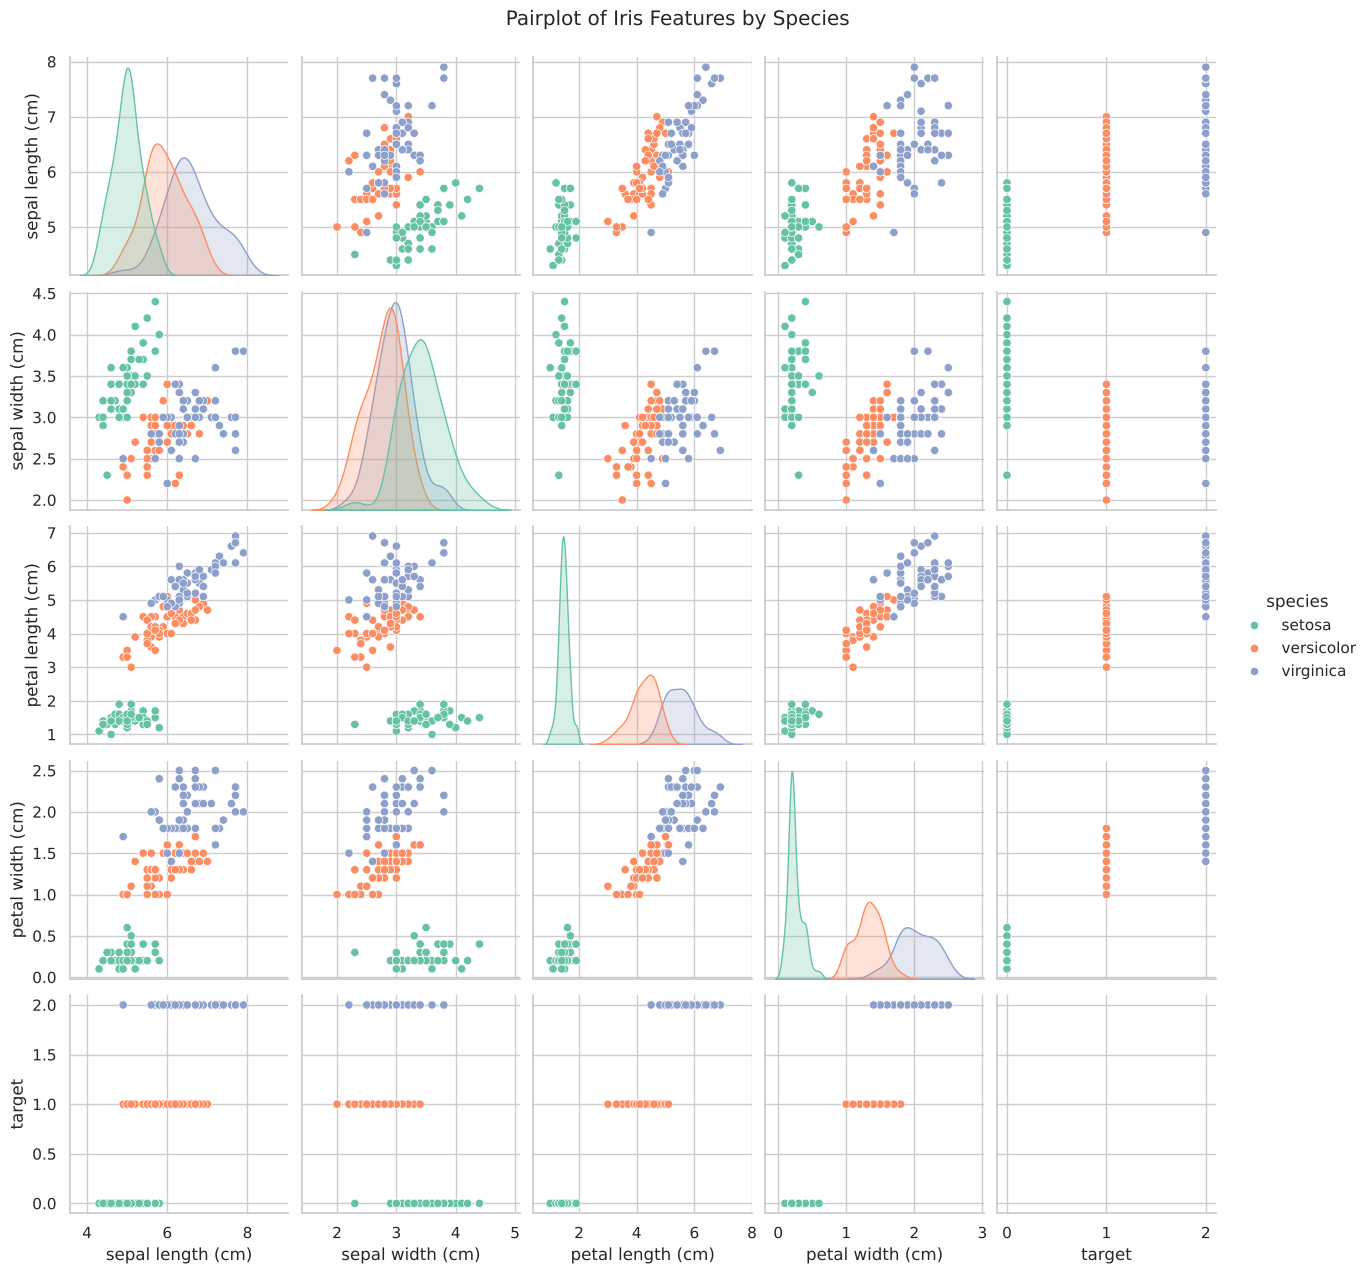

In [3]:
sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

## Train / test split

The split is **stratified** so every species appears in the same proportion in both parts, which matters with only 150 samples.

In [4]:
X = df[iris.feature_names]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

{'setosa': 35, 'versicolor': 35, 'virginica': 35} {'setosa': 15, 'versicolor': 15, 'virginica': 15}


## Baseline

A model that always predicts the most frequent class. Any real model must beat this.

In [5]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f"Majority-class baseline, test accuracy: {baseline.score(X_test, y_test):.3f}")

Majority-class baseline, test accuracy: 0.333


## Train a Decision Tree (depth fixed at 3 for illustration)

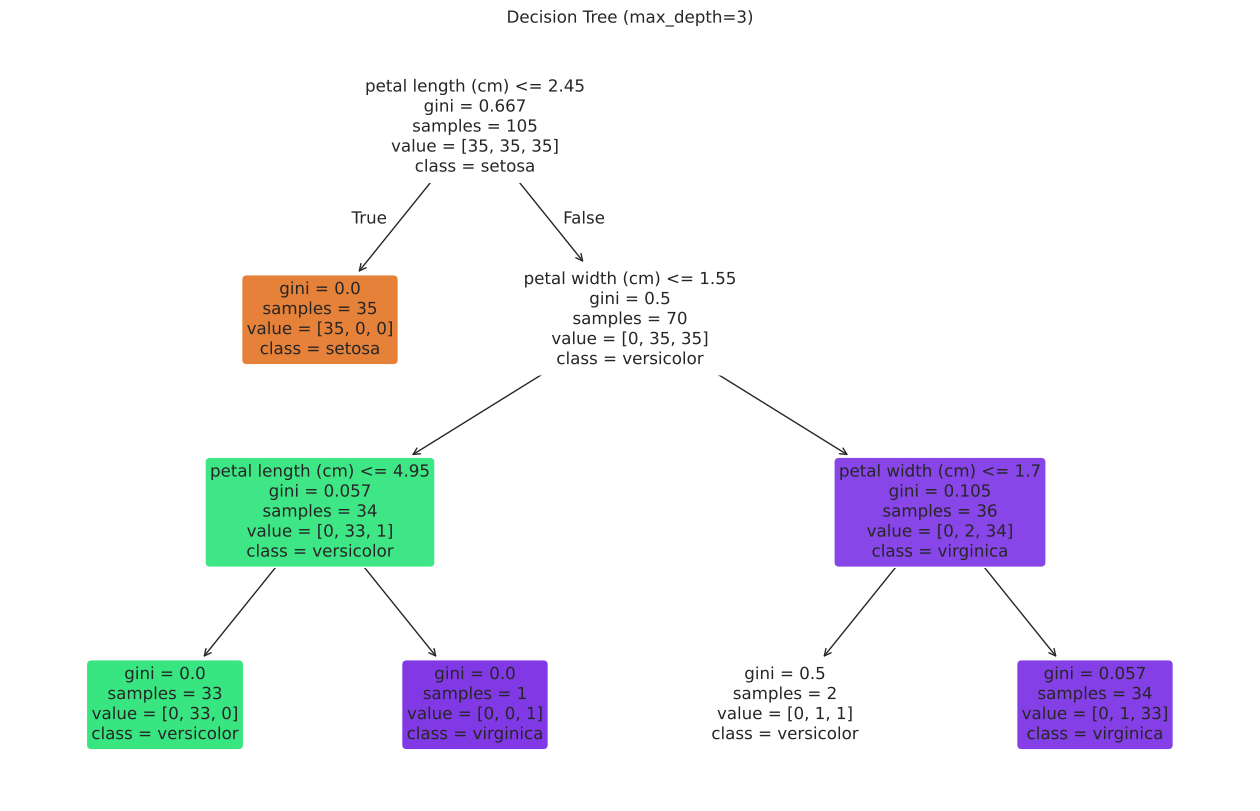

In [6]:
clf = DecisionTreeClassifier(random_state=42, max_depth=3)
clf.fit(X_train, y_train)

plt.figure(figsize=(16, 10))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=12)
plt.title("Decision Tree (max_depth=3)")
plt.show()

## Overfitting vs Underfitting

Training accuracy always rises with depth, so it says nothing about generalisation. The honest comparison is **cross-validated accuracy on the training data**, which is what the curve below shows. The test set is not used here.

,train_acc,cv_acc,cv_std
max_depth,,,
1,0.667,0.667,0.000
2,0.974,0.935,0.033
3,0.980,0.952,0.033
4,0.993,0.945,0.029
5,0.997,0.945,0.029
6,1.000,0.945,0.029
7,1.000,0.945,0.029
8,1.000,0.945,0.029
9,1.000,0.945,0.029


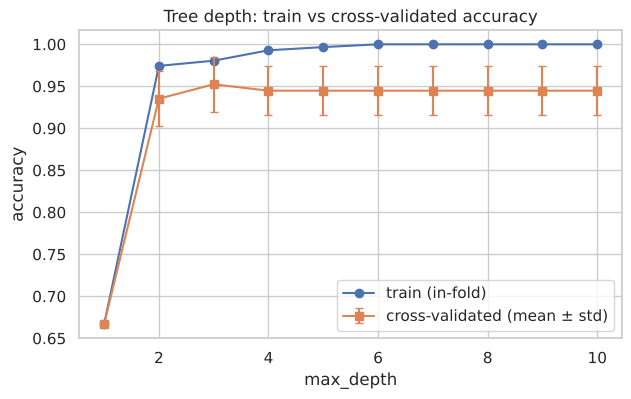

In [7]:
depths = list(range(1, 11))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

rows = []
for d in depths:
    res = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=0), X_train, y_train,
                         cv=cv, scoring='accuracy', return_train_score=True)
    rows.append((d, res['train_score'].mean(), res['test_score'].mean(), res['test_score'].std()))
depth_df = pd.DataFrame(rows, columns=['max_depth', 'train_acc', 'cv_acc', 'cv_std']).set_index('max_depth')
display(depth_df.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_df.index, depth_df.train_acc, 'o-', label='train (in-fold)')
ax.errorbar(depth_df.index, depth_df.cv_acc, yerr=depth_df.cv_std, fmt='s-', capsize=3, label='cross-validated (mean ± std)')
ax.set_xlabel('max_depth'); ax.set_ylabel('accuracy'); ax.set_title('Tree depth: train vs cross-validated accuracy')
ax.legend(); plt.show()

**Reading the curve.** Training accuracy climbs to ~1.0 while cross-validated accuracy plateaus after depth ≈ 2–3 and then stops improving; deeper trees only memorise the training points. The standard deviation bars show the differences between neighbouring depths are within noise, so the simplest depth near the plateau is the sensible choice.

## Feature Importance

Impurity-based importance (from the fitted tree) can favour features with many split points, so it is shown next to **permutation importance on the held-out test set**, which measures how much accuracy drops when a feature is shuffled.

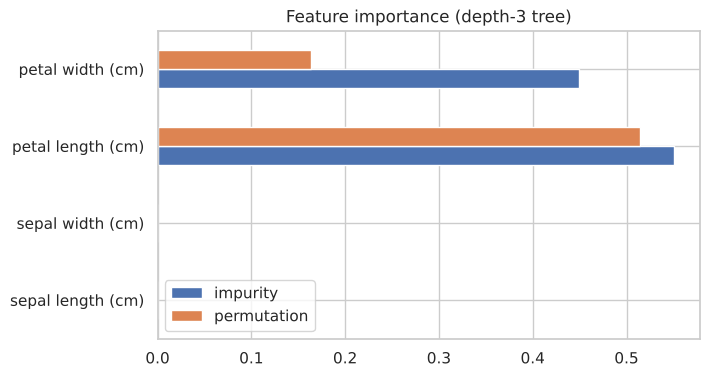

,impurity,permutation
sepal length (cm),0.000,0.000
sepal width (cm),0.000,0.000
petal length (cm),0.551,0.514
petal width (cm),0.449,0.164


In [8]:
perm = permutation_importance(clf, X_test, y_test, n_repeats=30, random_state=0)
imp = pd.DataFrame({'impurity': clf.feature_importances_,
                    'permutation': perm.importances_mean},
                   index=iris.feature_names)
imp.plot.barh(figsize=(7, 4), title='Feature importance (depth-3 tree)')
plt.show()
imp.round(3)

## Hyperparameter Tuning

Grid search runs 5-fold stratified CV on the **training set only**; the test set is not involved.

In [9]:
param_grid = {
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 4, 6],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    cv=StratifiedKFold(5, shuffle=True, random_state=42))
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Cross-validated accuracy of best setting (train only): {grid.best_score_:.3f}")

Best parameters: {'max_depth': 3, 'min_samples_split': 2}
Cross-validated accuracy of best setting (train only): 0.952


## Compare with Logistic Regression

Scaling is part of a `Pipeline`, so it is fitted on the training folds only.

In [10]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['setosa','versicolor','virginica']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Final comparison

1. **Repeated stratified 5×10 CV on all 150 rows** gives a stable estimate with uncertainty (for the tuned tree the hyper-parameters were chosen on the training split only, which is the small remaining optimism; see note below).
2. **Single test-set evaluation** of each model fitted on the training split.

In [11]:
models = {
    'majority baseline': DummyClassifier(strategy='most_frequent'),
    'decision tree (tuned)': grid.best_estimator_,
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
cv_final = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=1)
rows = []
for name, m in models.items():
    s = cross_val_score(clone(m), X, y, cv=cv_final, scoring='accuracy')
    m.fit(X_train, y_train)
    rows.append((name, s.mean(), s.std(), accuracy_score(y_test, m.predict(X_test))))
summary = pd.DataFrame(rows, columns=['model', 'cv_mean_acc', 'cv_std', 'test_acc']).set_index('model')
summary.round(3)

,cv_mean_acc,cv_std,test_acc
model,,,
majority baseline,0.333,0.000,0.333
decision tree (tuned),0.943,0.041,0.978
logistic regression,0.957,0.035,0.911


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



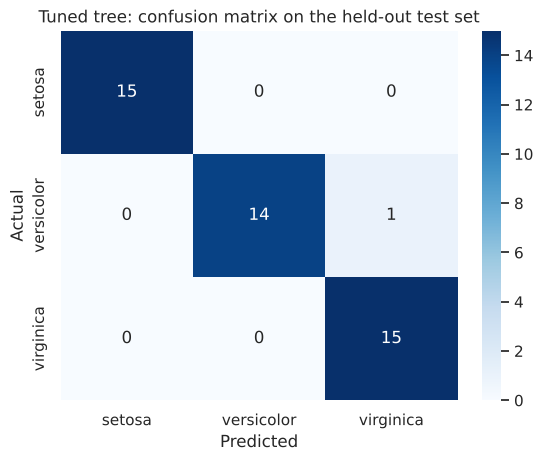

In [12]:
y_pred = grid.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Tuned tree: confusion matrix on the held-out test set")
plt.show()

## Methodology notes

- **Leakage:** all tuning used training data only; scaling lives inside a pipeline; the test set is read once for the final report.
- **Noise:** Iris is tiny and easy, so tree and logistic regression are statistically indistinguishable here (compare the CV std). Do not read a 1–2 point gap as a ranking.
- **Optimism:** the repeated-CV row for the tuned tree reuses hyper-parameters chosen on the training split, so it is slightly optimistic. Fully unbiased tuning would nest the grid search inside the outer CV loop (see the cross-validation project).
- **Generalisation:** Iris is a teaching dataset. Conclusions about depth and over-fitting transfer; the accuracy numbers do not.